# testing and clustering
## setup

In [1]:
import pandas as pd
import numpy as np
from collections import Counter
import os
import torch
from tqdm import tqdm
# preprocessing
from transformers import (
     pipeline,
)
import spacy
# ml
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    make_scorer,
    precision_score,
    recall_score,
    f1_score,
)
from sklearn.model_selection import cross_val_score, ShuffleSplit, train_test_split, GridSearchCV
from sklearn import svm
from sklearn import metrics
#plotting
import plotly.express as px
import plotly.io as pio
import matplotlib.pyplot as plt

In [2]:
## global variables and setup
MODEL = "../../projects/classifier/spatial-entities-classifier/models/modern-gbert-binary-nnse-best/"
CORPUS_PATH = "../corpora-collection/sunset-corpus/src/normalized/"
pio.templates.default="gridon"

In [3]:
## spacy
nlp = spacy.load("de_dep_news_trf", 
                 exclude=[
        "tagger",
        "morphologizer",
        "lemmatizer",
        "attribute_ruler",
    ],)

In [4]:
## load trained model
classifier = pipeline(
    task="token-classification",
    model=MODEL,
    tokenizer=MODEL,
    aggregation_strategy="none",
    device=0 if torch.cuda.is_available() else -1,
)

Loading weights:   0%|          | 0/138 [00:00<?, ?it/s]

In [5]:
# helper functions
def split_into_chunks(text: str, chunk_size: int = 300) -> list[str]:
    words = text.split()

    return [
        " ".join(words[i:i + chunk_size])
        for i in range(0, len(words), chunk_size)
    ]
def join_subwords(tokens: list[str]) -> list[str]:
    result = []

    for token in tokens:
        if token.startswith("##") and result:
            result[-1] += token[2:]
        else:
            result.append(token)

    return result
def create_document_pca(
    z_df: pd.DataFrame,
) -> tuple[pd.DataFrame, PCA]:
    """
    Reduce a document matrix to two PCA dimensions.

    Expected input:
        rows    = words
        columns = documents
        values  = z-scores
    """
    # Documents become rows; words become features.
    document_matrix = z_df.T

    if document_matrix.shape[0] < 2:
        raise ValueError("At least two documents are required.")

    if document_matrix.shape[1] < 2:
        raise ValueError("At least two word features are required.")

    pca = PCA(n_components=2)

    embedding = pca.fit_transform(document_matrix)

    pca_df = pd.DataFrame({
        "document": document_matrix.index,
        "pca_1": embedding[:, 0],
        "pca_2": embedding[:, 1],
    })

    return pca_df, pca

In [6]:
def create_nnse_counter_matrix(n_chunks=25):
    counter = WordCountMatrix()
    
    for file in tqdm(list(df.filename)):
        with open(CORPUS_PATH + file) as f:
            text = f.read()
        #chunk text
        chunks = split_into_chunks(text=text, chunk_size=300)
        # only look at beginning of text
        max_chunk_size = n_chunks
        if len(chunks)>max_chunk_size:
            chunks_to_process = chunks[:max_chunk_size]
        else:
            chunks_to_process = chunks
        # create sentences
        docs = nlp.pipe(chunks_to_process, batch_size=32, n_process=1)
        sentences = [
            sent.text
            for doc in docs
            for sent in doc.sents
        ]
        # extract nnse
        predictions = classifier(sentences)
        words_raw = [
            prediction["word"]
            for document_predictions in predictions
            for prediction in document_predictions
        ]
        words = join_subwords(words_raw)
        # update WordCountMatrix
        counter.update(words, column_name=file)
    return counter

In [7]:
class WordCountMatrix:
    def __init__(self):
        self.vocabulary: list[str] = []
        self._known_words: set[str] = set()
        self.documents: list[Counter] = []
        self.column_names: list[str] = []

    def update(
        self,
        words: list[str],
        column_name: str,
    ) -> None:
        """Add one word list as a named matrix column."""
        if column_name in self.column_names:
            raise ValueError(
                f"Column name already exists: {column_name}"
            )

        self.documents.append(Counter(words))
        self.column_names.append(column_name)

        for word in words:
            if word not in self._known_words:
                self._known_words.add(word)
                self.vocabulary.append(word)

    def update_many(
        self,
        word_lists: list[list[str]],
        column_names: list[str],
    ) -> None:
        """Add several named word lists."""
        if len(word_lists) != len(column_names):
            raise ValueError(
                "word_lists and column_names must have the same length."
            )

        for words, column_name in zip(word_lists, column_names):
            self.update(words, column_name)

    def to_dataframe(self) -> pd.DataFrame:
        """Return words as rows and word lists as columns."""
        data = {
            column_name: [
                document.get(word, 0)
                for word in self.vocabulary
            ]
            for column_name, document in zip(
                self.column_names,
                self.documents,
            )
        }

        return pd.DataFrame(
            data,
            index=self.vocabulary,
            dtype=float,
        )

    @staticmethod
    def _z_transform(
        df: pd.DataFrame,
        axis: int = 0,
    ) -> pd.DataFrame:
        """
        Apply a z-transformation.

        axis=0:
            Standardize each document column across words.

        axis=1:
            Standardize each word across documents.
        """
        if axis == 0:
            means = df.mean(axis=0)
            stds = df.std(axis=0, ddof=0).replace(0, 1)

            return (df - means) / stds

        if axis == 1:
            means = df.mean(axis=1)
            stds = df.std(axis=1, ddof=0).replace(0, 1)

            return df.sub(means, axis=0).div(stds, axis=0)

        raise ValueError("axis must be 0 or 1.")

    def to_z_dataframe(
        self,
        axis: int = 0,
    ) -> pd.DataFrame:
        """Return the complete z-transformed matrix."""
        df = self.to_dataframe()
        return self._z_transform(df, axis=axis)

    def most_frequent(
        self,
        n: int,
        z_transform: bool = False,
        axis: int = 0,
    ) -> pd.DataFrame:
        """
        Return the n most frequent words.

        Frequencies are calculated from the raw count matrix.
        The selected rows can optionally be z-transformed.
        """
        if n < 1:
            raise ValueError("n must be at least 1.")

        df = self.to_dataframe()

        # Select words using their raw total frequency.
        total_counts = df.sum(axis=1)
        selected_words = total_counts.nlargest(n).index

        result = df.loc[selected_words].copy()

        if z_transform:
            result = self._z_transform(
                result,
                axis=axis,
            )

        return result

    def to_numpy(self):
        """Return the complete count matrix as a NumPy array."""
        return self.to_dataframe().to_numpy()
    
    @classmethod
    def from_dataframe(
        cls,
        df: pd.DataFrame,
        ) -> "WordCountMatrix":
        """
        Create a WordCountMatrix from a pandas DataFrame.
    
        Expected format:
            rows    = words
            columns = documents
            values  = word counts
        """
        # Check for duplicate words or document names
        if df.index.has_duplicates:
            raise ValueError(
                "DataFrame index contains duplicate words."
            )
    
        if df.columns.has_duplicates:
            raise ValueError(
                "DataFrame contains duplicate column names."
            )
    
        # Check that all values are numeric
        if not all(
            pd.api.types.is_numeric_dtype(dtype)
            for dtype in df.dtypes
        ):
            raise ValueError(
                "All DataFrame values must be numeric."
            )
    
        # Create empty object
        matrix = cls()
    
        # Restore vocabulary
        matrix.vocabulary = df.index.tolist()
        matrix._known_words = set(matrix.vocabulary)
    
        # Restore document names
        matrix.column_names = df.columns.tolist()
    
        # Restore Counters
        for column_name in matrix.column_names:
            counts = df[column_name]
    
            document = Counter({
                word: count
                for word, count in counts.items()
                if count != 0
            })
    
            matrix.documents.append(document)

        return matrix

## setting up dataset

In [8]:
df = pd.read_csv("src/city_country_metadata.tsv", sep="\t")
len(df)

156

## loop for file sentenizing and extraction of words

In [9]:
# counter = create_nnse_counter_matrix(n_chunks=300)

In [10]:
# counter.to_dataframe().to_csv("src/results_raw.tsv", sep="\t", index=True)
counter = WordCountMatrix.from_dataframe(pd.read_csv("src/results_raw.tsv", sep="\t", index_col="Unnamed: 0"))

In [11]:
matrix = counter.most_frequent(
    n=2000,
    z_transform=True,
    axis=0,
)

## eyeballing the data

In [12]:
pca_df, pca_model = create_document_pca(matrix)

print("PC1:", pca_model.explained_variance_ratio_[0])
print("PC2:", pca_model.explained_variance_ratio_[1])
print("Total:", pca_model.explained_variance_ratio_.sum())

PC1: 0.11204118386942956
PC2: 0.07563937143173748
Total: 0.18768055530116703


In [13]:
pca_df["org_label"]=df.textClass

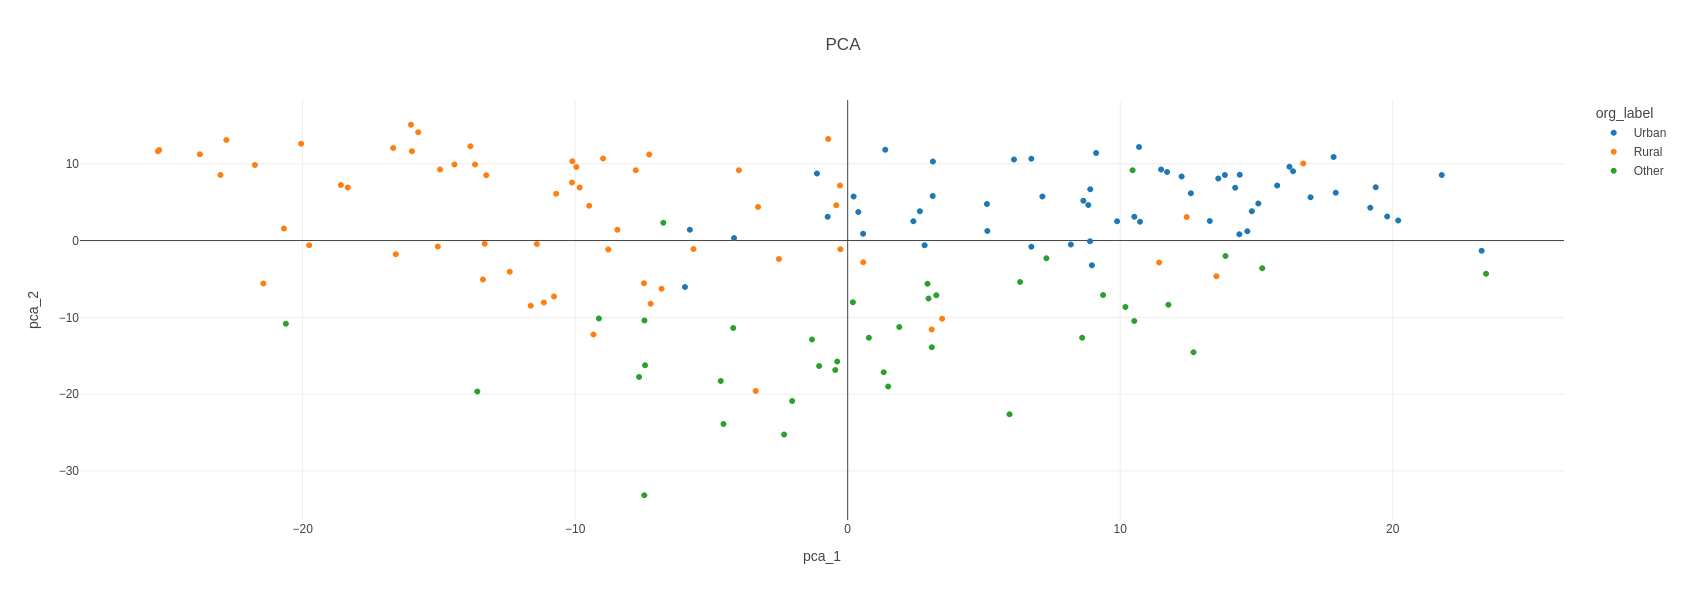

In [14]:
fig = px.scatter(pca_df, x="pca_1", y="pca_2",
                 color="org_label",
                 hover_data=["document", "org_label"],
                 height=600,
                 width=800,
                 title="PCA"
                )
fig.show()

## svm with k-fold validation 

In [15]:
param_grid = [
    {
        "kernel": ["linear"],
        "C": [0.01, 0.1, 1, 10, 100]
    },
    {
        "kernel": ["rbf"],
        "C": [0.1, 1, 10, 100],
        "gamma": ["scale", 0.01, 0.1, 1]
    },
    {
        "kernel": ["poly"],
        "C": [0.1, 1, 10],
        "gamma": ["scale", 0.01, 0.1],
        "degree": [2, 3],
        "coef0": [0, 1]
    }
]

In [16]:
scoring = {
    "precision_macro": make_scorer(
        precision_score,
        average="macro",
        zero_division=0,
    ),
    
    "recall_macro": make_scorer(
        recall_score,
        average="macro",
        zero_division=0,
    ),
    
    "f1_macro": make_scorer(
        f1_score,
        average="macro",
        zero_division=0,
    ),
}

In [17]:
# find best nnse

header = "mf-nnse\tbest_params\tf1\n"
with open("temp.tsv", "w") as f:
    f.write(header)
    
for i in range(50, 5050, 50):
    mat = counter.most_frequent(
        n=i,
        z_transform=True,
        axis=0,
    )
    
    X_train, X_test, y_train, y_test = train_test_split(mat.T.to_numpy(),
                                                    df.textClass,
                                                    test_size=0.20,
                                                    random_state=42,
                                                    stratify=df.textClass)

    grid_search = GridSearchCV(
        estimator=svm.SVC(),
        param_grid=param_grid,
        scoring=scoring,
        refit="f1_macro",
        cv=5,
        n_jobs=-1,
        verbose=1,
        return_train_score=True
    )

    grid_search.fit(X_train, y_train)
    
    row = f"{i}\t{grid_search.best_params_}\t{grid_search.best_score_}\n"
    with open("temp.tsv", "a") as f:
        f.write(row)

Fitting 5 folds for each of 57 candidates, totalling 285 fits
Fitting 5 folds for each of 57 candidates, totalling 285 fits
Fitting 5 folds for each of 57 candidates, totalling 285 fits
Fitting 5 folds for each of 57 candidates, totalling 285 fits
Fitting 5 folds for each of 57 candidates, totalling 285 fits
Fitting 5 folds for each of 57 candidates, totalling 285 fits
Fitting 5 folds for each of 57 candidates, totalling 285 fits
Fitting 5 folds for each of 57 candidates, totalling 285 fits
Fitting 5 folds for each of 57 candidates, totalling 285 fits
Fitting 5 folds for each of 57 candidates, totalling 285 fits
Fitting 5 folds for each of 57 candidates, totalling 285 fits
Fitting 5 folds for each of 57 candidates, totalling 285 fits
Fitting 5 folds for each of 57 candidates, totalling 285 fits
Fitting 5 folds for each of 57 candidates, totalling 285 fits
Fitting 5 folds for each of 57 candidates, totalling 285 fits
Fitting 5 folds for each of 57 candidates, totalling 285 fits
Fitting 

In [18]:
temp=pd.read_csv("temp.tsv", sep="\t")
temp.loc[temp.f1==temp.f1.max()]

,mf-nnse,best_params,f1
5,300,"{'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}",0.879859


<Axes: xlabel='mf-nnse'>

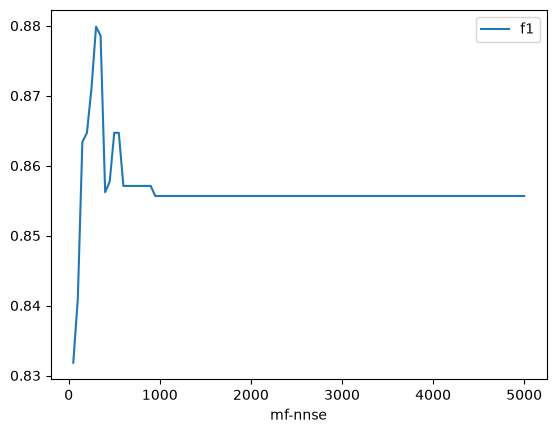

In [19]:
temp.plot(x="mf-nnse", y="f1", kind="line")

In [20]:
# setup dataset
X_train, X_test, y_train, y_test = train_test_split(matrix.T.to_numpy(),
                                                    df.textClass,
                                                    test_size=0.20,
                                                    random_state=42,
                                                    stratify=df.textClass)

In [21]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_train)

svm_2d = svm.SVC(
    kernel="rbf",
    C=10,
    gamma=0.01,
)

svm_2d.fit(X_pca, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",10
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.01
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [22]:
x_min = X_pca[:, 0].min() - 1
x_max = X_pca[:, 0].max() + 1

y_min = X_pca[:, 1].min() - 1
y_max = X_pca[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 500),
    np.linspace(y_min, y_max, 500)
)

In [23]:
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y_train)

grid = np.c_[xx.ravel(), yy.ravel()]

Z = svm_2d.predict(grid)

Z_encoded = encoder.transform(Z)
Z_encoded = Z_encoded.reshape(xx.shape)

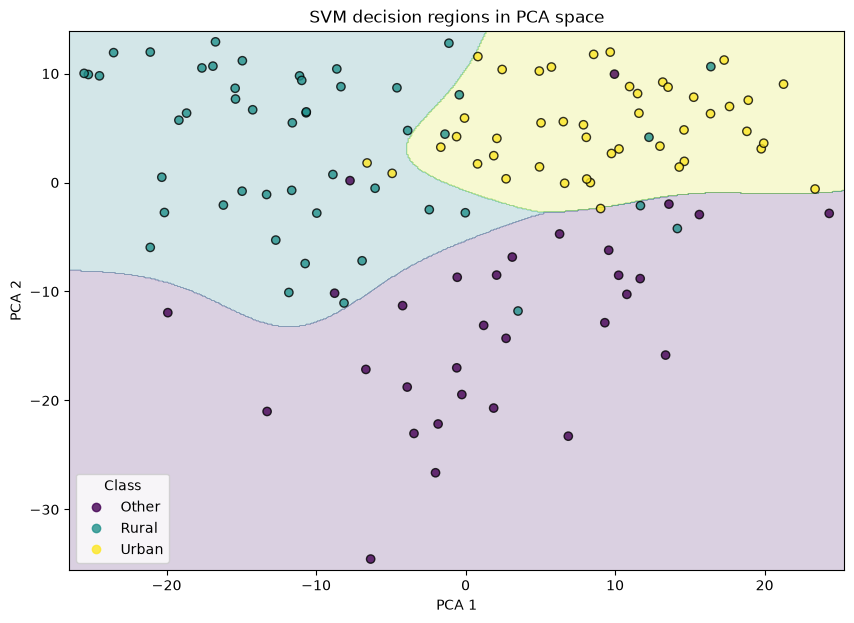

In [24]:
plt.figure(figsize=(10, 7))

# Decision regions
plt.contourf(
    xx,
    yy,
    Z_encoded,
    alpha=0.2
)

# Actual observations
scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y_encoded,
    edgecolors="black",
    alpha=0.8
)

plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("SVM decision regions in PCA space")

plt.legend(
    handles=scatter.legend_elements()[0],
    labels=encoder.classes_,
    title="Class"
)

plt.show()

In [25]:
model = svm.SVC(
    kernel="rbf",
    C=10,
    gamma=0.01,
)

In [26]:
mat = counter.most_frequent(
        n=300,
        z_transform=True,
        axis=0,
    )
    
X_train, X_test, y_train, y_test = train_test_split(mat.T.to_numpy(),
                                                    df.textClass,
                                                    test_size=0.20,
                                                    random_state=42,
                                                    stratify=df.textClass)

In [27]:
model.fit(X_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",10
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.01
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [28]:
y_pred = model.predict(X_test)

In [29]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       Other       0.80      1.00      0.89         8
       Rural       0.85      0.85      0.85        13
       Urban       1.00      0.82      0.90        11

    accuracy                           0.88        32
   macro avg       0.88      0.89      0.88        32
weighted avg       0.89      0.88      0.88        32



In [30]:
len(y_train)

124

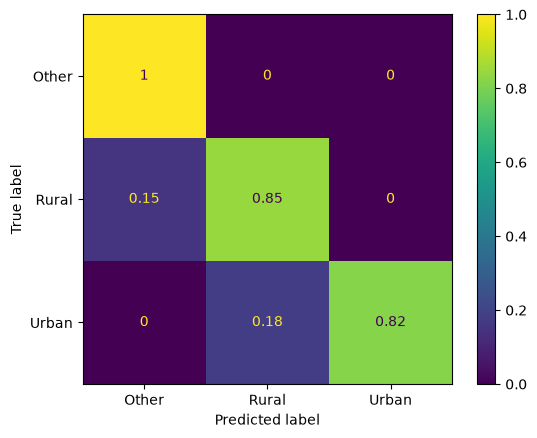

In [31]:
cm = confusion_matrix(y_true=y_test, y_pred=y_pred, labels=["Other", "Rural", "Urban"], normalize="true")
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Other", "Rural", "Urban"])
disp.plot()